In [2]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import load_iris
from sklearn.cluster import AgglomerativeClustering
from scipy.cluster.hierarchy import dendrogram, linkage
from scipy.optimize import linear_sum_assignment
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)

In [3]:
iris = load_iris()
X = iris.data
y = iris.target

print(f"No. of samples: {X.shape[0]}")
print(f"No. of features: {X.shape[1]}")
print("\nClassification Report: ")
for i in np.unique(y):
  print(f"{iris.target_names[i]}: {np.sum(y==i)}")

No. of samples: 150
No. of features: 4

Classification Report: 
setosa: 50
versicolor: 50
virginica: 50


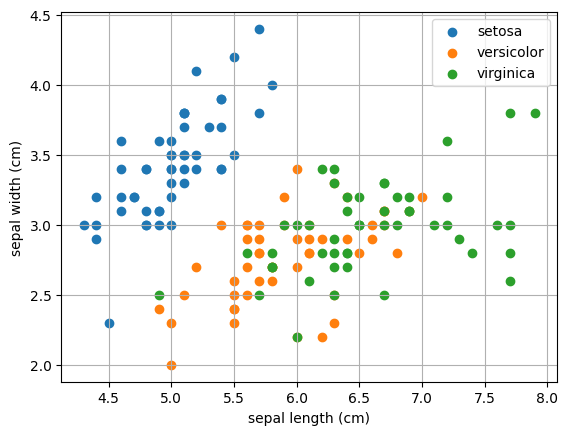

In [4]:
plt.scatter(X[y==0,0], X[y==0,1], label=iris.target_names[0])
plt.scatter(X[y==1,0], X[y==1,1], label=iris.target_names[1])
plt.scatter(X[y==2,0], X[y==2,1], label=iris.target_names[2])
plt.xlabel(f"{iris.feature_names[0]}")
plt.ylabel(f"{iris.feature_names[1]}")
plt.legend()
plt.grid()
plt.show()

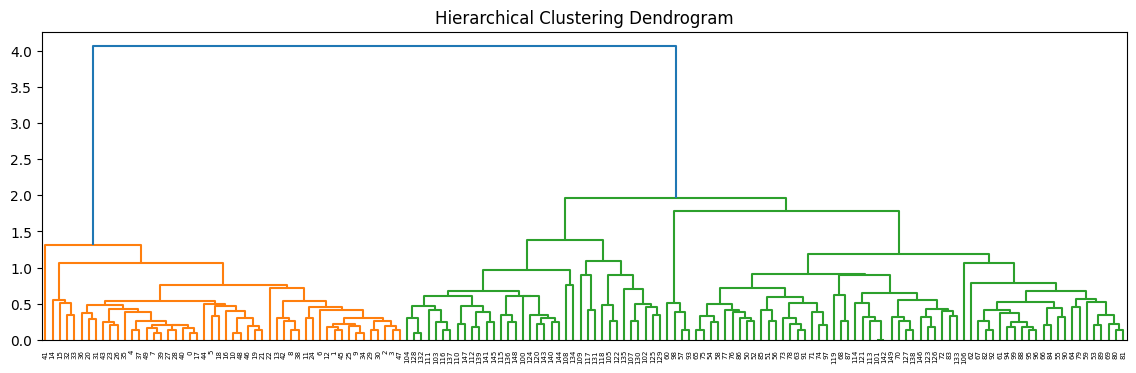

In [7]:
Z = linkage(X, method='average')
plt.figure(figsize=(14,4))
plt.title("Hierarchical Clustering Dendrogram")
dendrogram(Z)
plt.show()


Linkage: single
Accuracy: 0.6800
Precision: 0.8367
Recall: 0.6800
F1 score: 0.5842
Confusion matrix: 
[[50  0  0]
 [ 0 50  0]
 [ 0 48  2]]


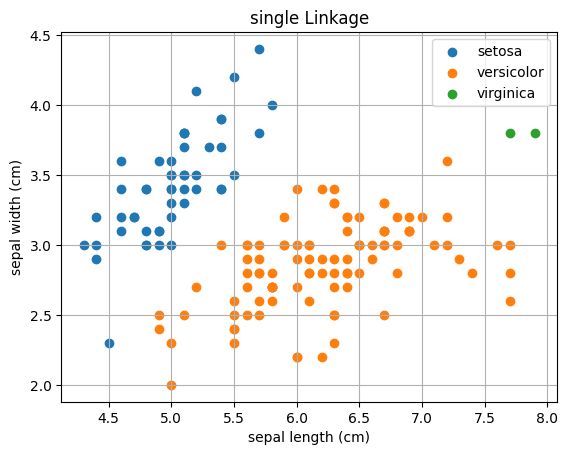


Linkage: complete
Accuracy: 0.8400
Precision: 0.8816
Recall: 0.8400
F1 score: 0.8319
Confusion matrix: 
[[50  0  0]
 [ 0 27 23]
 [ 0  1 49]]


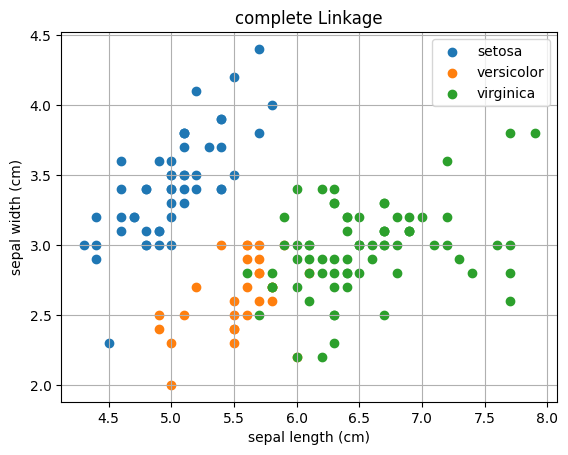


Linkage: average
Accuracy: 0.9067
Precision: 0.9271
Recall: 0.9067
F1 score: 0.9048
Confusion matrix: 
[[50  0  0]
 [ 0 50  0]
 [ 0 14 36]]


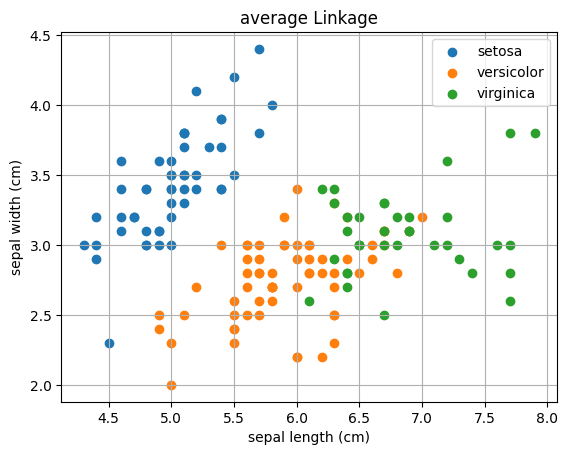


Linkage: ward
Accuracy: 0.8933
Precision: 0.9126
Recall: 0.8933
F1 score: 0.8912
Confusion matrix: 
[[50  0  0]
 [ 0 49  1]
 [ 0 15 35]]


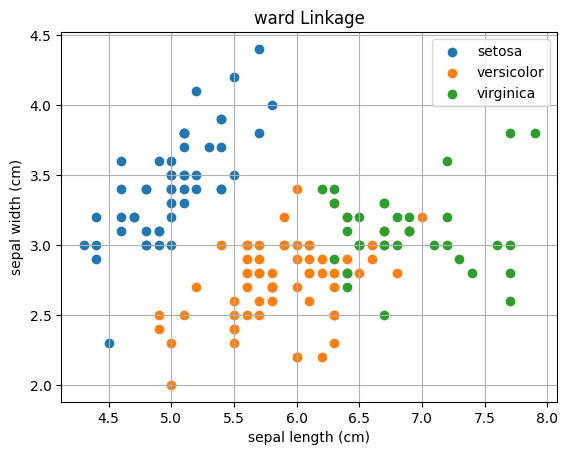

In [12]:
methods = ['single', 'complete', 'average', 'ward']

for method in methods:
  model = AgglomerativeClustering(
      n_clusters = 3,
      linkage = method
  )
  pred = model.fit_predict(X)

  cm = confusion_matrix(y, pred)
  r,c = linear_sum_assignment(-cm)
  mapping = dict(zip(c, r))
  pred = np.array([mapping[i] for i in pred])

  print("\n"+"="*100)
  print(f"Linkage: {method}")
  print(f"Accuracy: {accuracy_score(y, pred):.4f}")
  print(f"Precision: {precision_score(y, pred, average='macro'):.4f}")
  print(f"Recall: {recall_score(y, pred, average='macro'):.4f}")
  print(f"F1 score: {f1_score(y, pred, average='macro'):.4f}")
  print(f"Confusion matrix: \n{confusion_matrix(y, pred)}")

  plt.title(method + " Linkage")
  plt.scatter(X[pred==0,0], X[pred==0,1], label=iris.target_names[0])
  plt.scatter(X[pred==1,0], X[pred==1,1], label=iris.target_names[1])
  plt.scatter(X[pred==2,0], X[pred==2,1], label=iris.target_names[2])
  plt.xlabel(f"{iris.feature_names[0]}")
  plt.ylabel(f"{iris.feature_names[1]}")
  plt.legend()
  plt.grid()
  plt.show()
